# Lab 1: CICIDS2017

One notebook, seven parts. Run from top to bottom in the **lab1** folder. Data: `../cicids2017_raw.parquet`. Outputs: `notebook_results/`. Older scripts and results are unchanged.

This uses the **full dataset**, both tasks, three protocols, four model families, six k values, and five shuffle seeds. Standard kNN can take a long time.

This version uses ordinary scikit-learn pipelines and built-in plotting/metric helpers. Its full-data run completed on 11 October 2026 in 32.4 minutes: all 3,119,345 raw rows loaded, 24 model evaluations, 60 validation scores, eight probes, and 12 figures. The executed outputs below and refreshed report are from this run. Code has no comments or progress prints.


## Setup

Import the libraries once. `save` displays and saves a table; `figure` displays and saves a graph. The repeated steps live in these small helpers.


In [1]:
# SETUP. We load the libraries, fix the seed (42) so every run gives the same result, and read the
# full CICIDS2017 table (one row = one flow). `features` is the hand-picked list of 19 behavioural
# features the models use: timing, volume, packet sizes, flags. No IPs, ports or time, because those
# describe the scenario, not the behaviour.
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve, roc_curve

SEED=42
out = Path("notebook_results")
out.mkdir(exist_ok=True)
df=pd.read_parquet("../cicids2017_raw.parquet")
features = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets", "Fwd Packet Length Mean",
    "Bwd Packet Length Mean", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean",
    "Fwd IAT Mean", "Bwd IAT Mean", "SYN Flag Count", "ACK Flag Count", "Down/Up Ratio",
    "Average Packet Size", "Init_Win_bytes_forward", "Active Mean", "Idle Mean"]

# save: takes a table and a name. Shows the table in the notebook and writes it to
# notebook_results/<name>.csv, so every number in the report has a file behind it.
def save(table, name):
    display(table)
    table.to_csv(out / (name+".csv"))

# figure: takes a name. Saves the current plot as notebook_results/<name>.png, shows it, then closes
# it to free memory.
def figure(name):
    plt.tight_layout()
    plt.savefig(out / (name+".png"), dpi=180)
    plt.show()
    plt.close()


## Part 1: How the data were collected

Each row describes a bidirectional network flow, not a single packet. Monday contains benign traffic only. The existing schedule is summarized below; some attack subtypes share an interval.

| Day | Attack | Time | Attacker | Victim | Service / tool |
| --- | --- | --- | --- | --- | --- |
| Tuesday | FTP-Patator | 09:20-10:20 | 205.174.165.73 | 192.168.10.50 | FTP / Patator |
| Tuesday | SSH-Patator | 14:00-15:00 | 205.174.165.73 | 192.168.10.50 | SSH / Patator |
| Wednesday | DoS attacks | 09:47-11:23 | 205.174.165.73 | 192.168.10.50 | HTTP / slowloris, Hulk, others |
| Wednesday | Heartbleed | 15:12-15:32 | 205.174.165.73 | 192.168.10.51 | Port 444 / Heartbleed |
| Thursday | Web attacks | 09:20-10:42 | 205.174.165.73 | 192.168.10.50 | HTTP / brute force, XSS, SQLi |
| Thursday | Infiltration | 14:19-15:45 | 205.174.165.73 | Vista / Mac | Mixed / Metasploit, Nmap |
| Friday | Bot | 10:02-11:02 | 205.174.165.73 | Several Windows PCs | Mixed / ARES |
| Friday | PortScan | 13:55-15:29 | 205.174.165.73 | 192.168.10.50 | Many ports / Nmap |
| Friday | DDoS | 15:56-16:16 | 205.174.165.69-71 | 192.168.10.50 | HTTP / LOIT (official page's spelling) |

Time, IPs, ports, protocol, and source file can act as shortcuts. Detecting an attack mechanism means recognizing relevant traffic behavior; recognizing a particular host or Friday afternoon may only recognize the capture setup.

Before plotting: (1) DoS Hulk should have an unusual packet-rate distribution; (2) FTP brute force should produce repeated, relatively regular short flows. These are hypotheses, not conclusions.

Schedule checked against [official dataset documentation](https://www.unb.ca/cic/datasets/ids-2017.html).


## Part 2: Splits and data audit

Create the protocols before label-informed graphs. Hash buckets keep identical predictor vectors together under random splitting and identical ordered five-tuples together under grouped splitting. Chronological flows cannot cross a time boundary.

This deliberately retains the existing **hash-based random protocol**, which is approximately 70/15/15 but **not stratified**. The assignment asks for stratification; this remains a limitation of the existing method, not something notebook packaging fixes. Keep this distinction in the report.

`Dexplore` is simply the rows marked training under **all three protocols**. Only these rows are used for label-informed feature graphs. Each model still uses its own full training partition.


In [2]:
# PART 2: THE THREE SPLITS. We build the random, grouped and chronological splits BEFORE drawing any
# plot coloured by label, so no choice can be influenced by validation or test data.
save(pd.Series({"rows":len(df), "columns":len(df.columns),
    "source files":df["source_file"].nunique()}), "dataset")
df=df.set_index("row_id")
# predictors = every numeric column except the ports and protocol. These are the values we hash for
# the random split.
numbers = list(df.select_dtypes(include="number").columns)
predictors=[c for c in numbers if c not in ["Source Port", "Destination Port", "Protocol"]]
# Read each flow's timestamp. `good` = the rows we can use: they have a label AND a valid time.
times=pd.to_datetime(df["Timestamp"], format="mixed", dayfirst=True, errors="coerce")
good = df["Label"].notna() & times.notna()
# One hash number per row. vectors: computed from the feature values, so identical flows get the
# same number. groups: computed from the five-tuple, so all flows of one connection get the same
# number.
vectors=pd.util.hash_pandas_object(df[predictors], index=False)
groups = pd.util.hash_pandas_object(df[["Source IP", "Destination IP",
    "Source Port", "Destination Port", "Protocol"]], index=False)

# split: takes a bucket number 0-99 for every row. Gives three masks: buckets 0-69 -> train, 70-84
# -> validation, 85-99 -> test. Same bucket = same set, so copies can never end up in two sets.
def split(bucket):
    return {"train":good & (bucket<70),
        "val":good & (bucket>=70) & (bucket<85), "test":good & (bucket>=85)}

# Random split from the feature hash, grouped split from the five-tuple hash. `% 100` turns a huge
# hash into a bucket 0-99.
random, grouped = split(vectors % 100), split(groups % 100)
# Chronological split. cut1/cut2 = the 70% and 85% points in time. A flow's END = start + duration.
# Train flows must END before cut1; validation flows start after cut1 and end before cut2; test
# flows start after cut2. A flow crossing a cutoff fits none of these and is left out (it is counted
# in the audit).
cut1, cut2=times[good].quantile([0.70, 0.85])
ends=times + pd.to_timedelta(df["Flow Duration"].clip(lower=0), unit="us")
chrono={"train":good & (ends<=cut1),
    "val":good & (times>cut1) & (ends<=cut2), "test":good & (times>cut2)}
protocols = {"random":random, "grouped":grouped, "chrono":chrono}
# D_explore = rows that are TRAINING rows in all three splits (974,803). Only these rows are used
# for label-coloured plots, so we never look at any test row.
explore=random["train"] & grouped["train"] & chrono["train"]
# Save the row IDs of every set and count each class in each set.
ids, counts = {}, []
labels=sorted(df.loc[good, "Label"].unique())
for protocol, parts in protocols.items():
    ids[protocol]=[df.index[mask] for mask in parts.values()]
    for part, mask in parts.items():
        pd.Series(df.index[mask], name="row_id").to_csv(out / (protocol+"_"+part+"_ids.csv"), index=False)
        frequency=df.loc[mask, "Label"].value_counts()
        counts.extend([[protocol, part, label, frequency.get(label, 0)] for label in labels])
save(pd.DataFrame(counts, columns=["protocol", "set", "label", "count"]), "class_counts")
pd.Series(df.index[explore], name="row_id").to_csv(out / "dexplore_ids.csv", index=False)
save(pd.Series({"Dexplore":int(explore.sum()), "cut1":cut1, "cut2":cut2}), "cutoffs")
# Safety checks: no hash is shared between two sets, and no chronological flow crosses its time
# boundary. If one fails, the notebook stops.
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(vectors[random[a]]).isdisjoint(vectors[random[b]])
    assert set(groups[grouped[a]]).isdisjoint(groups[grouped[b]])
assert ends[chrono["train"]].max()<=cut1
assert times[chrono["val"]].min()>cut1 and ends[chrono["val"]].max()<=cut2
assert times[chrono["test"]].min()>cut2


rows            3119345
columns              87
source files          8
dtype: int64

,protocol,set,label,count
0,random,train,BENIGN,1590546
1,random,train,Bot,1417
2,random,train,DDoS,89731
3,random,train,DoS GoldenEye,7232
4,random,train,DoS Hulk,167817
...,...,...,...,...
130,chrono,test,PortScan,0
131,chrono,test,SSH-Patator,0
132,chrono,test,Web Attack - Brute Force,0
133,chrono,test,Web Attack - Sql Injection,0


Dexplore                 974803
cut1        2017-07-06 09:27:00
cut2        2017-07-07 03:23:00
dtype: object

,missing,positive_inf,negative_inf
ACK Flag Count,288602,0.0,0.0
Active Max,288602,0.0,0.0
Active Mean,288602,0.0,0.0
Active Min,288602,0.0,0.0
Active Std,288602,0.0,0.0
...,...,...,...
Total Length of Bwd Packets,288602,0.0,0.0
Total Length of Fwd Packets,288602,0.0,0.0
URG Flag Count,288602,0.0,0.0
act_data_pkt_fwd,288602,0.0,0.0


,problem,affected,treatment and reason
0,missing labels,288602.0,exclude: no supervised answer
1,infinite cells,4376.0,training median
2,bad timestamps,0.0,exclude: cannot assign time
3,boundary-crossing flows,6407.0,exclude: overlaps periods
4,raw duplicate copies,288804.0,keep together to avoid leakage
5,repeated predictor copies,885178.0,same random hash bucket
6,conflicting-label rows,82865.0,keep: ambiguity is not proof of mislabeling
7,duplicate column,1.0,exclude Fwd Header Length.1: redundant


Series([], dtype: str)

,protocol,feature,unique,largest_share
0,random,Bwd PSH Flags,1,1.000000
1,random,Fwd URG Flags,2,0.999921
2,random,Bwd URG Flags,1,1.000000
3,random,RST Flag Count,2,0.999763
4,random,CWE Flag Count,2,0.999921
5,random,ECE Flag Count,2,0.999762
6,random,Fwd Avg Bytes/Bulk,1,1.000000
7,random,Fwd Avg Packets/Bulk,1,1.000000
8,random,Fwd Avg Bulk Rate,1,1.000000
9,random,Bwd Avg Bytes/Bulk,1,1.000000


,raw,Dexplore
Label,,
BENIGN,2273097,839377
Bot,1966,0
DDoS,128027,0
DoS GoldenEye,10293,5061
DoS Hulk,231073,117599
DoS Slowhttptest,5499,2687
DoS slowloris,5796,2829
FTP-Patator,7938,4061
Heartbleed,11,8


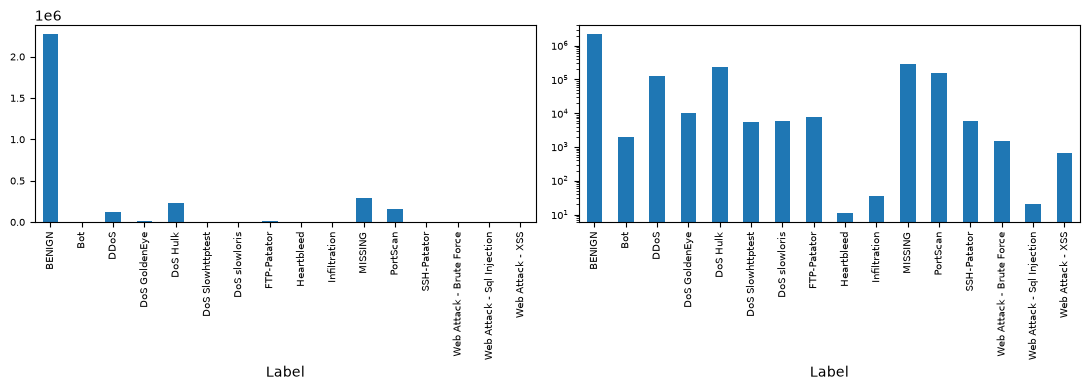

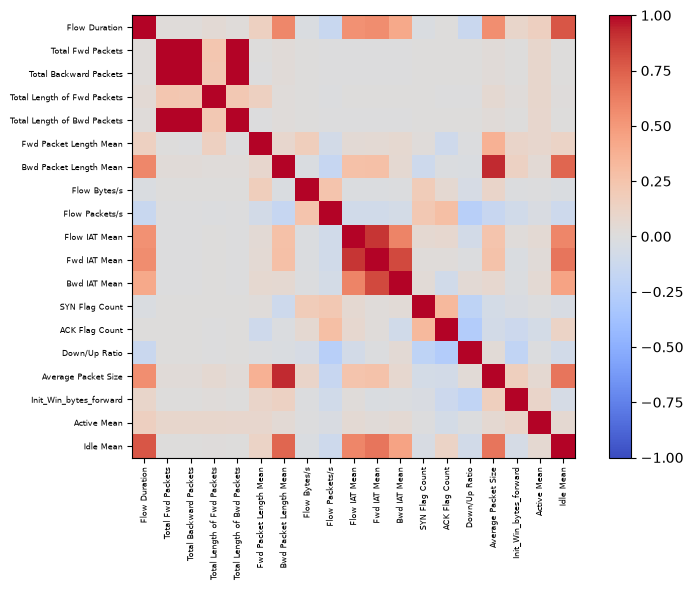

In [3]:
# DATA AUDIT. We count every data problem and write down how it is treated. Nothing is silently
# deleted.
# Count missing values and +inf/-inf per column.
invalid=pd.DataFrame({"missing":df.isna().sum(),
    "positive_inf":df[numbers].eq(np.inf).sum(), "negative_inf":df[numbers].eq(-np.inf).sum()}).fillna(0)
save(invalid[invalid.sum(axis=1)>0], "invalid_values")
# Group rows by their feature hash, to find identical feature vectors carrying different labels.
by_vector=df.groupby(vectors)["Label"]
# The audit table: each problem, how many rows, and the treatment with its reason.
quality=pd.DataFrame([
    ["missing labels", df["Label"].isna().sum(), "exclude: no supervised answer"],
    ["infinite cells", invalid[["positive_inf", "negative_inf"]].sum().sum(), "training median"],
    ["bad timestamps", (times.isna() & df["Timestamp"].notna()).sum(), "exclude: cannot assign time"],
    ["boundary-crossing flows", (good & ~(chrono["train"] | chrono["val"] | chrono["test"])).sum(), "exclude: overlaps periods"],
    ["raw duplicate copies", df.duplicated().sum(), "keep together to avoid leakage"],
    ["repeated predictor copies", vectors.duplicated().sum(), "same random hash bucket"],
    ["conflicting-label rows", by_vector.size()[by_vector.nunique()>1].sum(), "keep: ambiguity is not proof of mislabeling"],
    ["duplicate column", int(df["Fwd Header Length"].equals(df["Fwd Header Length.1"])),
        "exclude Fwd Header Length.1: redundant"]], columns=["problem", "affected", "treatment and reason"])
save(quality, "quality")
save(pd.Series(df.columns[df.columns.str.strip()!=df.columns]), "inconsistent_column_names")
# Near-constant features: one value covers at least 99% of the training rows (per split).
low=[]
for protocol, parts in protocols.items():
    for name in predictors:
        values=df.loc[parts["train"], name]
        share=values.value_counts(dropna=False, normalize=True).iloc[0]
        if share>=0.99:
            low.append([protocol, name, values.nunique(dropna=False), share])
save(pd.DataFrame(low, columns=["protocol", "feature", "unique", "largest_share"]), "low_variance")
# Class counts in the raw data and in D_explore, plotted on a normal and a log scale (the log scale
# makes tiny classes like Heartbleed visible).
frequency=pd.DataFrame({"raw":df["Label"].fillna("MISSING").value_counts(),
    "Dexplore":df.loc[explore, "Label"].value_counts()}).fillna(0).astype(int)
save(frequency, "frequency")
fig, axes=plt.subplots(1, 2, figsize=(11, 4))
for i in range(2):
    frequency["raw"].plot.bar(ax=axes[i], logy=(i==1), fontsize=7)
figure("class_frequency")
# x = the model inputs: the 19 features with infinities turned into missing values. The correlation
# heatmap is computed on D_explore only.
x=df[features].replace([np.inf, -np.inf], np.nan)
fig, ax=plt.subplots(figsize=(8, 6))
image=ax.imshow(x.loc[explore].corr(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(features)), features, rotation=90, fontsize=6)
ax.set_yticks(range(len(features)), features, fontsize=6)
fig.colorbar(image, ax=ax)
figure("correlation")
# Keep only the columns still needed, to save memory. This drops columns, not rows.
df=df[["Label", "Timestamp", "source_file", "Source IP", "Destination IP",
    "Source Port", "Destination Port", "Protocol"]+features]


After the audit, retain only the model inputs and reconstruction metadata to save memory. This removes unused columns, not rows. The raw audit is not feature selection. Missing labels/timestamps are excluded through `good`; their counts remain visible. Infinities are filled later using training medians. Nearly constant columns are flagged; the explicitly declared behavioral list determines model inputs. Conflicting labels show ambiguity, not which label is wrong. Packet-capture errors cannot be proved from these flow summaries alone.

## Part 3: Attack behavior

The 19 features cover volume, packet size, timing, directionality, TCP flags, and activity. Compare benign traffic, DoS Hulk, and FTP brute force using safe training rows. The ECDF's vertical value is the fraction at or below a given value; log(1+x) compresses large values.


Flow Duration                          Flow Packets/s  \
                      min      median          max            min   
Label                                                               
BENIGN               -2.0     30846.0  119999997.0  -2.000000e+06   
DoS Hulk              1.0  84713133.0  119968626.0   1.748631e-02   
FTP-Patator           1.0       289.0   10780124.0   2.226319e+00   

                                     Average Packet Size              \
                   median        max                 min      median   
Label                                                                  
BENIGN         127.473788  4000000.0                 0.0   73.500000   
DoS Hulk         0.164223  3000000.0                 0.0  852.785714   
FTP-Patator  10380.622840  3000000.0                 0.0   12.208333   

                          
                     max  
Label                     
BENIGN       3893.333333  
DoS Hulk     1995.833333  
FTP-Patator    14.000000

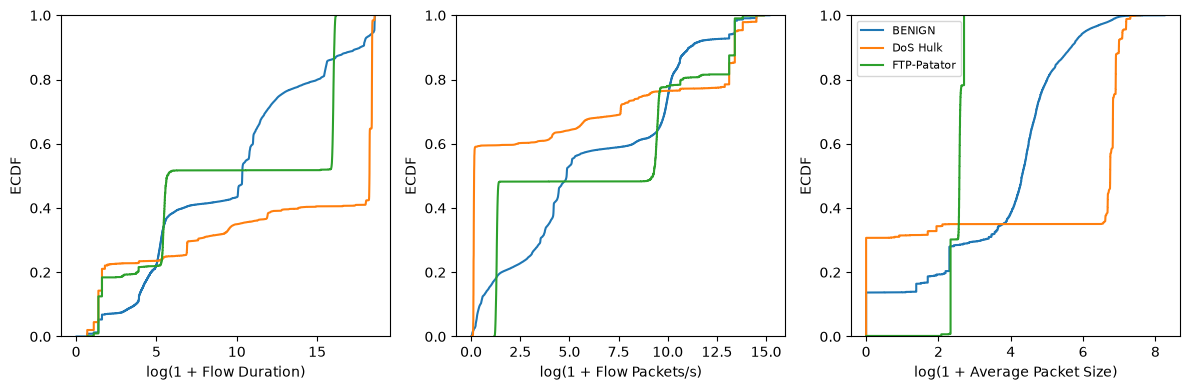

In [4]:
# PART 3: ECDF PLOTS. We take benign, DoS Hulk and FTP-Patator rows from D_explore only, show the
# min/median/max of three features, and draw their ECDFs on a log(1+x) axis to test the two
# hypotheses written beforehand. clip(lower=0) is needed because log(1+x) breaks for values <= -1.
fields=["Flow Duration", "Flow Packets/s", "Average Packet Size"]
behavior=df.loc[explore & df["Label"].isin(["BENIGN", "DoS Hulk", "FTP-Patator"]), ["Label"]+fields]
behavior = behavior.replace([np.inf, -np.inf], np.nan).dropna()
save(behavior.groupby("Label")[fields].agg(["min", "median", "max"]), "feature_ranges")
fig, axes=plt.subplots(1, 3, figsize=(12, 4))
for field, ax in zip(fields, axes):
    for label, group in behavior.groupby("Label"):
        ax.ecdf(np.log1p(group[field].clip(lower=0)), label=label)
    ax.set(xlabel="log(1 + "+field+")", ylabel="ECDF")
axes[2].legend(fontsize=8)
figure("attack_behavior")


Every complete row of the selected classes in Dexplore is used. There is no runtime sampling.

Observed here: FTP-Patator has short, high-rate flows (median duration 289 microseconds; 10,380.62 packets/s). Hulk has long flows and a low median packet rate (84,713,133 microseconds; 0.164 packets/s). These distributions support differences in behavior, but the tools, fixed servers, and CICFlowMeter construction are competing explanations. Negative measurements are clipped to zero for the log plots only, not for modeling.

## Part 4: Baselines

A scikit-learn pipeline joins median imputation, optional scaling, and the classifier. Calling `fit` learns all three from training only; `predict` reuses them unchanged. Trees and the majority baseline are not scaled. `classification_report` supplies F1 scores and per-class recall without repeated metric calls.

Validation chooses attack F1 for binary and macro F1 for multiclass. Fixed choices: tree depth 3; C = 0.1 or 1; k = 1, 3, 5, 7, 9, 11; seed 42. The same loop handles every protocol.


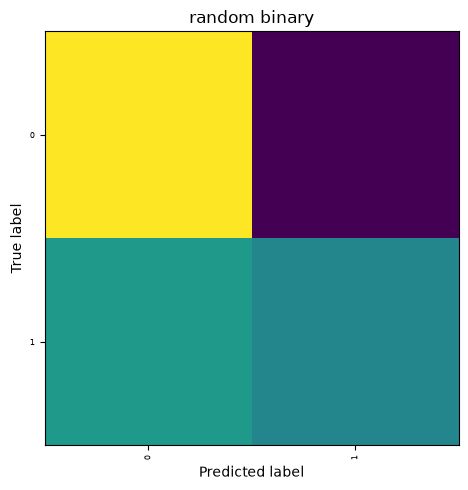

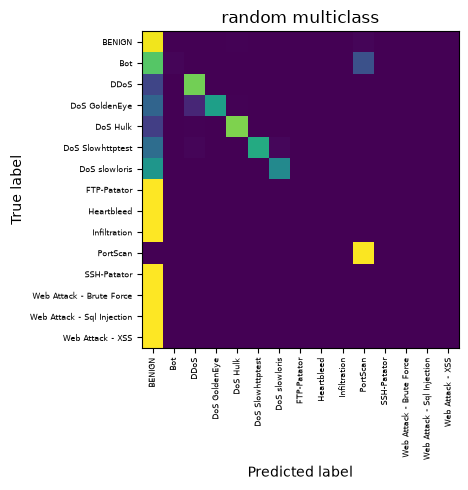

,protocol,task,model,setting,balanced_accuracy,macro_f1,weighted_f1,attack_f1
0,random,binary,majority,-,0.500000,0.448978,0.731665,0.000000
1,random,binary,tree,depth=3,0.901619,0.885190,0.929233,0.815240
2,random,binary,logistic,C=1,0.726152,0.777301,0.878772,0.616140
3,random,binary,knn,k=7,0.890509,0.925031,0.956598,0.874895
4,random,multiclass,majority,-,0.066667,0.059864,0.731665,NaN
5,random,multiclass,tree,depth=3,0.225123,0.230086,0.924709,NaN
6,random,multiclass,logistic,C=1,0.348740,0.374267,0.946138,NaN
7,random,multiclass,knn,k=1,0.681390,0.699481,0.938146,NaN


In [5]:
# PART 4: BASELINES.
# pipeline: takes a model and whether to scale. Gives imputer (training median) -> scaler (only for
# logistic regression and kNN) -> model. Calling fit on training rows learns the medians and scales
# from training only, which prevents leakage.
def pipeline(model, scale=False):
    return make_pipeline(SimpleImputer(strategy="median"),
        StandardScaler() if scale else "passthrough", model)

metrics, tuning, recalls, importance = [], [], [], []
# run: takes a split name. For binary and multiclass, it trains the four model families, picks each
# one's best setting on VALIDATION (attack F1 for binary, macro F1 for multiclass), then scores the
# winner ONCE on test. It records balanced accuracy, macro and weighted F1, attack F1, per-class
# recall, the tree's importances and the logistic confusion matrix.
def run(protocol):
    train, val, test=ids[protocol]
    for task in ["binary", "multiclass"]:
        y=(df["Label"]!="BENIGN").astype(int) if task=="binary" else df["Label"]
        average="binary" if task=="binary" else "macro"
        # The candidates: majority class (the floor), a depth-3 tree (not tuned), logistic
        # regression with C in {0.1, 1}, kNN with k in {1, 3, 5, 7, 9, 11}.
        models={"majority":[("-", DummyClassifier(strategy="most_frequent"))],
            "tree":[("depth=3", DecisionTreeClassifier(max_depth=3, random_state=SEED))],
            "logistic":[("C="+str(c), LogisticRegression(C=c, max_iter=1000, random_state=SEED)) for c in [0.1, 1]],
            "knn":[("k="+str(k), KNeighborsClassifier(n_neighbors=k, algorithm="kd_tree", n_jobs=-1)) for k in [1, 3, 5, 7, 9, 11]]}
        for name, candidates in models.items():
            best=-1
            # Train each setting on train, score it on validation, keep the best (strict >, so the
            # first one wins a tie).
            for setting, estimator in candidates:
                model=pipeline(estimator, name in ["logistic", "knn"])
                model.fit(x.loc[train], y.loc[train])
                score=f1_score(y.loc[val], model.predict(x.loc[val]), average=average, zero_division=0)
                tuning.append([protocol, task, name, setting, score])
                if score>best:
                    best, chosen, selected = score, model, setting
            # Only the chosen setting ever sees the test set.
            prediction=chosen.predict(x.loc[test])
            report=classification_report(y.loc[test], prediction, output_dict=True, zero_division=0)
            attack=report["1"]["f1-score"] if task=="binary" else np.nan
            metrics.append([protocol, task, name, selected, balanced_accuracy_score(y.loc[test], prediction),
                report["macro avg"]["f1-score"], report["weighted avg"]["f1-score"], attack])
            for label in sorted(set(y.loc[test]) | set(prediction)):
                recalls.append([protocol, task, name, label, report[str(label)]["recall"]])
            # Save the binary tree's feature importances and its printed rules.
            if name=="tree" and task=="binary":
                tree=chosen[-1]
                importance.extend([[protocol, f, v] for f, v in zip(features, tree.feature_importances_)])
                if protocol=="random":
                    _=(out / "tree_rules.txt").write_text(export_text(tree, feature_names=features))
            if name=="logistic":
                fig, ax=plt.subplots(figsize=(6, 5))
                ConfusionMatrixDisplay.from_predictions(y.loc[test], prediction, normalize="true",
                    include_values=False, xticks_rotation=90, colorbar=False, ax=ax)
                ax.set_title(protocol+" "+task)
                ax.tick_params(labelsize=6)
                figure(protocol+"_"+task+"_confusion")

metric_columns=["protocol", "task", "model", "setting", "balanced_accuracy", "macro_f1", "weighted_f1", "attack_f1"]
# Part 4 itself: the baselines on the random split.
run("random")
display(pd.DataFrame(metrics, columns=metric_columns))


Macro F1 gives each class equal weight; weighted F1 gives common classes more influence. A high weighted score can hide failure on rare attacks. Confusion matrices above are for logistic regression: rows are actual classes and columns are predictions. Class-wise recall is saved for every model. Read `notebook_results/tree_rules.txt` to interpret the depth-3 tree: behavioral measurements can still contain capture-specific thresholds.

## Part 5: Compare protocols

Random asks about another flow from a similar mixture; grouped asks about unseen five-tuples; chronological asks about later traffic. Reuse the exact same training loop. Attack classes absent from training are an open-set limitation, not simply evidence of leakage removal.


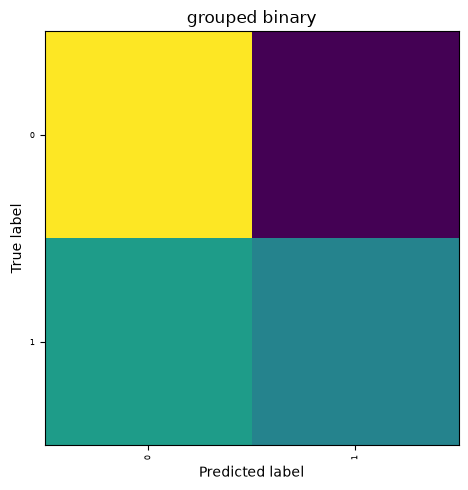

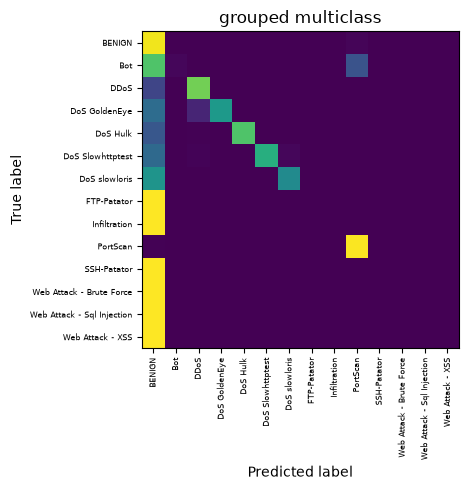

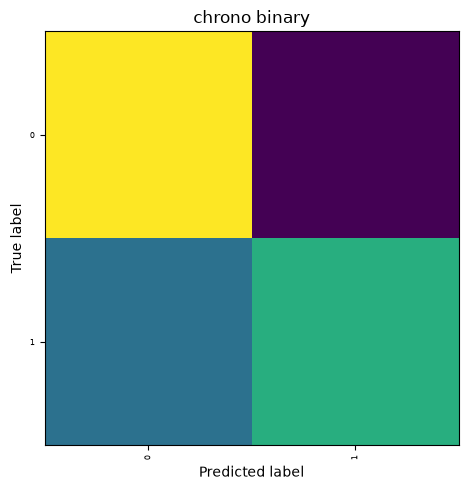

/Users/blinkyy/Downloads/lab1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/Users/blinkyy/Downloads/lab1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


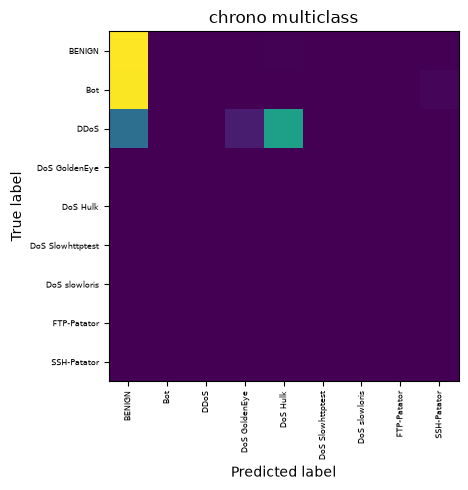

/Users/blinkyy/Downloads/lab1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,protocol,task,model,setting,balanced_accuracy,macro_f1,weighted_f1,attack_f1
0,random,binary,majority,-,0.500000,0.448978,0.731665,0.000000
1,random,binary,tree,depth=3,0.901619,0.885190,0.929233,0.815240
2,random,binary,logistic,C=1,0.726152,0.777301,0.878772,0.616140
3,random,binary,knn,k=7,0.890509,0.925031,0.956598,0.874895
4,random,multiclass,majority,-,0.066667,0.059864,0.731665,NaN
5,random,multiclass,tree,depth=3,0.225123,0.230086,0.924709,NaN
6,random,multiclass,logistic,C=1,0.348740,0.374267,0.946138,NaN
7,random,multiclass,knn,k=1,0.681390,0.699481,0.938146,NaN
8,grouped,binary,majority,-,0.500000,0.446118,0.718643,0.000000
9,grouped,binary,tree,depth=3,0.876115,0.876699,0.922772,0.801279


,protocol,task,model,setting,validation_f1
0,random,binary,majority,-,0.000000
1,random,binary,tree,depth=3,0.794664
2,random,binary,logistic,C=0.1,0.630756
3,random,binary,logistic,C=1,0.645897
4,random,binary,knn,k=1,0.913212
5,random,binary,knn,k=3,0.917689
6,random,binary,knn,k=5,0.917401
7,random,binary,knn,k=7,0.919958
8,random,binary,knn,k=9,0.919786
9,random,binary,knn,k=11,0.919661


,protocol,task,model,class,recall
0,random,binary,majority,0,1.000000
1,random,binary,majority,1,0.000000
2,random,binary,tree,0,0.943216
3,random,binary,tree,1,0.860022
4,random,binary,logistic,0,0.992625
...,...,...,...,...,...
162,chrono,multiclass,knn,DoS slowloris,0.000000
163,chrono,multiclass,knn,FTP-Patator,0.000000
164,chrono,multiclass,knn,Infiltration,0.000000
165,chrono,multiclass,knn,SSH-Patator,0.000000


,protocol,unseen_test_class
0,chrono,Bot
1,chrono,DDoS


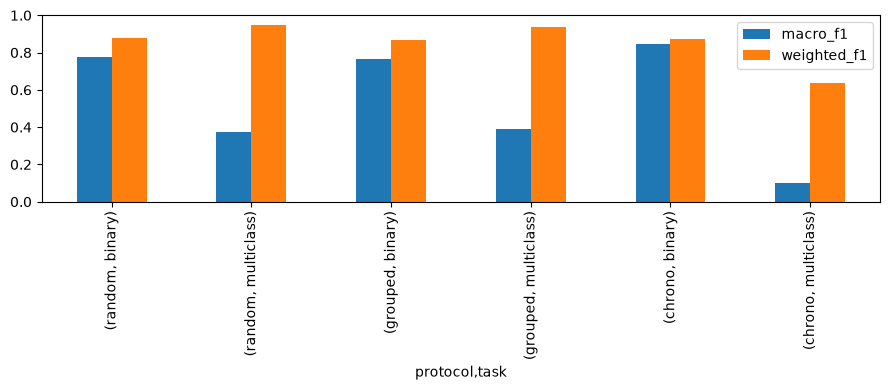

In [6]:
# PART 5: SAME MODELS ON THE GROUPED AND CHRONOLOGICAL SPLITS. We rerun everything, save all tables,
# and list test classes never seen in training: the open-set check (DDoS and Bot in the
# chronological split).
for protocol in ["grouped", "chrono"]:
    run(protocol)
results=pd.DataFrame(metrics, columns=metric_columns)
save(results, "metrics")
save(pd.DataFrame(tuning, columns=["protocol", "task", "model", "setting", "validation_f1"]), "validation")
save(pd.DataFrame(recalls, columns=["protocol", "task", "model", "class", "recall"]), "recall")
unseen=[]
for protocol, (train, val, test) in ids.items():
    unseen.extend([[protocol, label] for label in sorted(set(df.loc[test, "Label"])-set(df.loc[train, "Label"]))])
save(pd.DataFrame(unseen, columns=["protocol", "unseen_test_class"]), "unseen_classes")
# Plot logistic regression's macro and weighted F1 under each split.
comparison=results[results["model"]=="logistic"].set_index(["protocol", "task"])
comparison[["macro_f1", "weighted_f1"]].plot.bar(figsize=(9, 4), ylim=(0, 1))
figure("protocol_comparison")


## Part 6: Shortcut probes

Use the grouped split, chosen because unseen connections are closer to deployment than repeated flows. Each probe refits a depth-3 tree and its training-only imputer. Metadata and behavioral inputs do not overlap.

IP codes come from training addresses; unknown addresses become -1. Correlations also use training only: keep a feature only if no already-kept feature has absolute correlation above 0.9. Five shuffle seeds change training labels only.


0                   Flow Duration
1               Total Fwd Packets
2     Total Length of Fwd Packets
3          Fwd Packet Length Mean
4          Bwd Packet Length Mean
5                    Flow Bytes/s
6                  Flow Packets/s
7                   Flow IAT Mean
8                    Bwd IAT Mean
9                  SYN Flag Count
10                 ACK Flag Count
11                  Down/Up Ratio
12         Init_Win_bytes_forward
13                    Active Mean
14                      Idle Mean
Name: feature, dtype: str

,balanced_accuracy,macro_f1
probe,,
metadata,0.998756,0.999125
behavior,0.876115,0.876699
reduced,0.850667,0.892786
shuffle 1,0.499999,0.446118
shuffle 7,0.499990,0.446113
shuffle 21,0.500000,0.446118
shuffle 42,0.500002,0.446129
shuffle 99,0.499997,0.446117


,protocol,feature,importance
0,random,Flow Duration,0.000000
1,random,Total Fwd Packets,0.000000
2,random,Total Backward Packets,0.000000
3,random,Total Length of Fwd Packets,0.000000
4,random,Total Length of Bwd Packets,0.046734
5,random,Fwd Packet Length Mean,0.000000
6,random,Bwd Packet Length Mean,0.531760
7,random,Flow Bytes/s,0.119182
8,random,Flow Packets/s,0.000000
9,random,Flow IAT Mean,0.000000


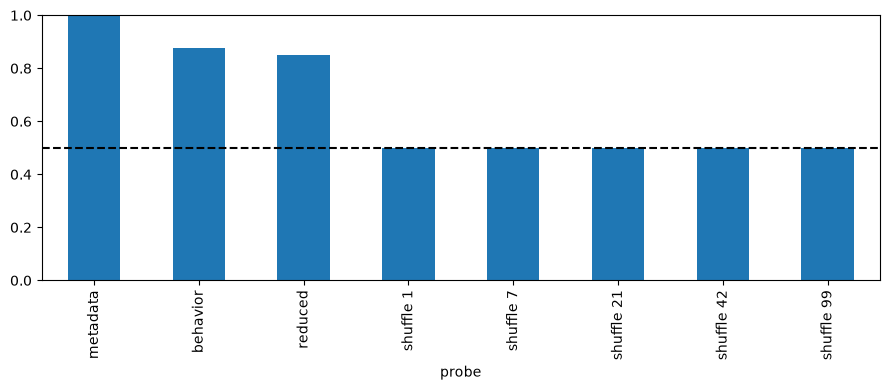

In [7]:
# PART 6: SHORTCUT PROBES on the grouped split. The same depth-3 tree every time; only the feature
# list changes.
train, val, test=ids["grouped"]
metadata=["Source IP", "Destination IP", "Source Port", "Destination Port", "Protocol", "hour", "day"]
# Add hour and day as metadata. IPs are text, so each training IP gets an integer code; an IP never
# seen in training gets -1.
df["hour"], df["day"] = times.dt.hour, times.dt.dayofweek
for name in ["Source IP", "Destination IP"]:
    known={value:i for i, value in enumerate(df.loc[train, name].dropna().unique())}
    df[name]=df[name].map(known).fillna(-1)
# Reduced set: go through the features in order and keep one only if it is not correlated above |r|
# = 0.9 with a feature already kept (correlation from training rows).
corr=x.loc[train].corr().abs()
reduced=[]
for name in features:
    if not any(corr.loc[name, previous]>0.9 for previous in reduced):
        reduced.append(name)
save(pd.Series(reduced, name="feature"), "reduced_features")
# The probes: metadata only, behaviour only, reduced behaviour, and 5 runs with shuffled training
# labels (seeds 1, 7, 21, 42, 99) = the chance level.
probes=[("metadata", metadata, None), ("behavior", features, None), ("reduced", reduced, None)]
probes += [("shuffle "+str(seed), features, seed) for seed in [1, 7, 21, 42, 99]]
y=(df["Label"]!="BENIGN").astype(int)
rows=[]
# For each probe: shuffle the TRAINING labels if there is a seed (test labels stay true), fit the
# tree, score balanced accuracy on test.
for name, columns, seed in probes:
    values=df[columns].replace([np.inf, -np.inf], np.nan)
    labels=y.loc[train].to_numpy()
    if seed is not None:
        labels=np.random.default_rng(seed).permutation(labels)
    model=pipeline(DecisionTreeClassifier(max_depth=3, random_state=SEED))
    model.fit(values.loc[train], labels)
    prediction=model.predict(values.loc[test])
    rows.append([name, balanced_accuracy_score(y.loc[test], prediction),
        f1_score(y.loc[test], prediction, average="macro", zero_division=0)])
probes=pd.DataFrame(rows, columns=["probe", "balanced_accuracy", "macro_f1"]).set_index("probe")
save(probes, "shortcut_probes")
save(pd.DataFrame(importance, columns=["protocol", "feature", "importance"]), "tree_importance")
# Bar chart; the dashed line at 0.5 is chance.
probes["balanced_accuracy"].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.axhline(0.5, color="black", linestyle="--")
figure("shortcut_probes")


Balanced accuracy 0.5 is the binary always-one-class null. Metadata success suggests scenario dependence, not proof of accidental leakage. Tree importance is impurity reduction, not causation; we reuse the fitted behavioral trees rather than refitting them.

## Part 7: Operational threshold

Fit grouped binary logistic regression with fixed C=0.1. Filter validation ROC points to FPR at most 1%, then choose the first with maximum attack recall. Apply that threshold to test once. The test FPR may exceed 1%.


threshold                  0.533671
test_recall                0.415641
test_fpr                   0.009933
false_alarms_per_100k    993.278284
test_precision             0.909975
dtype: float64

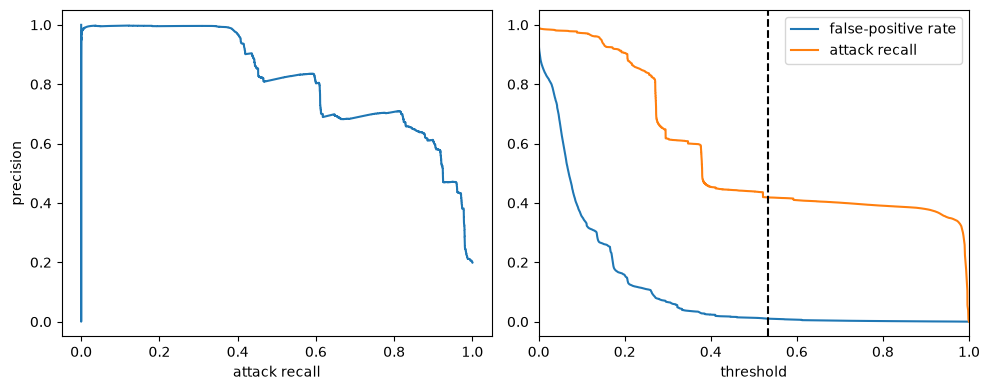

assumed_attack_prevalence    0.010000
expected_precision           0.297102
dtype: float64

In [8]:
# PART 7: OPERATIONAL THRESHOLD (grouped split). We pick a threshold on VALIDATION that keeps false
# positives at or below 1%, apply it once to test, and translate it into analyst workload.
model=pipeline(LogisticRegression(C=0.1, max_iter=1000, random_state=SEED), scale=True)
model.fit(x.loc[train], y.loc[train])
probability=model.predict_proba(x.loc[val])[:, 1]
# roc_curve lists every threshold with its FPR and recall on validation. Keep the thresholds with
# FPR <= 1% and take the one with the highest recall (0.534).
fpr, tpr, thresholds=roc_curve(y.loc[val], probability)
valid=fpr<=0.01
threshold=thresholds[valid][tpr[valid].argmax()]
# Apply that fixed threshold to test once, then compute recall, FPR, precision and false alarms per
# 100,000 benign flows.
prediction=(model.predict_proba(x.loc[test])[:, 1]>=threshold).astype(int)
tn, fp, fn, tp=confusion_matrix(y.loc[test], prediction, labels=[0, 1]).ravel()
operational=pd.Series({"threshold":threshold, "test_recall":tp/(tp+fn),
    "test_fpr":fp/(fp+tn), "false_alarms_per_100k":100000*fp/(fp+tn), "test_precision":tp/(tp+fp)})
save(operational, "operational")
# The two plots (validation data): the precision-recall curve, and FPR and recall against the
# threshold, with the chosen threshold dashed.
precision, recall, _=precision_recall_curve(y.loc[val], probability)
fig, axes=plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(recall, precision)
axes[0].set(xlabel="attack recall", ylabel="precision")
axes[1].plot(thresholds, fpr, label="false-positive rate")
axes[1].plot(thresholds, tpr, label="attack recall")
axes[1].axvline(threshold, color="black", linestyle="--")
axes[1].set(xlim=(0, 1), xlabel="threshold")
axes[1].legend()
figure("operational")
# Precision if only 1% of real traffic were attacks: about 0.30.
prevalence=0.01
expected_precision=prevalence*operational["test_recall"] / (prevalence*operational["test_recall"]+(1-prevalence)*operational["test_fpr"])
save(pd.Series({"assumed_attack_prevalence":prevalence, "expected_precision":expected_precision}), "deployment")


A 1% false-positive target limits analyst workload; raising the threshold usually misses more attacks but reduces false alerts. This is a workload constraint, not a cost-optimal claim. A real deployment must assign explicit costs to missed attacks and analyst review before selecting an operational threshold.

The last calculation assumes attacks are 1% of deployment flows. Precision can fall when attacks become rarer even if recall and FPR stay the same. A high CICIDS2017 test precision therefore cannot be copied directly into a production claim.

## Final discussion and model card

The full run reproduced the main findings: logistic multiclass macro F1 fell from 0.374 (random) to 0.102 (chronological); metadata-only balanced accuracy was 0.999; five shuffled-label probes stayed near 0.500. Standard kNN produced updated scores and selected k=7/1, 11/3, 11/3 for random, grouped, chronological (binary/multiclass). See notebook_results/metrics.csv and the refreshed report. The chronological warnings about predicted classes absent from the true labels reflect different class coverage, not a failed run.

Explain the biggest protocol change with class coverage, class balance, time, hosts, and services in mind. Check `unseen_classes.csv` before attributing any decrease to leakage removal. Repeatedly strong benign performance and weak rare-class recall can coexist with a high weighted F1.

**Model card:** Educational CICIDS2017 flow classifier. Evaluation uses the declared hash-random, ordered-five-tuple grouped, and globally chronological protocols, with training-only preprocessing and validation-selected settings. Known limitations include class imbalance, conflicting labels, missing-label exclusions, scenario-specific hosts/tools, non-stratified random allocation, and unseen chronological attack categories. Supported use: compare these experiments inside CICIDS2017. Unsupported claims: production-ready IDS, zero-day detection, attack attribution, or generalization to a new organization. New benign and attack captures from independent hosts, networks, days, and implementations are needed.
